# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching, so the
branching-only correlation and module notebooks are not produced; the unconditional EMT-TF
expression step is the last notebook.)*

We read a broad EMT-TF panel — not only Snail/Zeb/Twist but also the mesenchymal FOXC and PRRX
families (Kürten evaluation lesson) — gate each factor on detectable expression, and overlay the
most-detected factors on the manifold in the house categorical style.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold
The rooted manifold carries pseudotime `t` and the house linear layout `X_umap_lin`; the
malignant expression matrix is unchanged from `processed.h5ad`, so EMT-TF levels are read
directly from it.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 33067 | pseudotime range 0.0 -> 7.63


### Derive the EMT-TFs (data-driven) — and the detection finding
For each candidate TF present in the data: fraction of cells expressing it, mean expression in
the early (root) vs late (terminus) pseudotime tercile, and Spearman correlation with pseudotime.

**Multiple-myeloma plasma cells are not epithelial and do not undergo a classic EMT, so this
panel is expected to be near-silent** — and on this shallow MARS-seq data only **ZEB1** is
detectably expressed (~3% of cells); every other candidate sits below 0.3% of cells. There is
therefore no genuine root-to-terminus TF pair to derive: we report the panel-wide detection
table, overlay the most-detected factors by identity, and flag the EMT-TF program as essentially
absent.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t']).sort_values('frac_expr', ascending=False)
print('candidate panel present:', present)
print(df.to_string(index=False))
detectable = df[df.frac_expr > 0.01]['TF'].tolist()
show_tfs = df['TF'].tolist()[:2]   # two most-detected factors for the overlay
print()
print('detectable EMT-TFs (>1% of cells):', detectable if detectable else 'NONE')
print('EMT-TFs shown (two most-detected):', show_tfs,
      '| fractions:', {g: float(df.set_index('TF').loc[g,'frac_expr']) for g in show_tfs})
print('verdict: EMT-TF program essentially absent in this MM manifold (only ZEB1 clears ~3%).')

candidate panel present: ['SNAI1', 'SNAI2', 'ZEB1', 'ZEB2', 'TWIST1', 'TWIST2', 'FOXC1', 'FOXC2', 'PRRX1', 'PRRX2']
    TF  frac_expr  mean_early  mean_late  rho_vs_t
  ZEB1      0.032       0.018      0.022     0.023
 SNAI2      0.002       0.001      0.002     0.016
 PRRX1      0.002       0.001      0.002     0.023
  ZEB2      0.002       0.001      0.002     0.023
 SNAI1      0.001       0.000      0.000     0.008
TWIST1      0.001       0.001      0.001     0.007
TWIST2      0.000       0.000      0.000     0.008
 FOXC1      0.000       0.000      0.000    -0.004
 FOXC2      0.000       0.000      0.000     0.012
 PRRX2      0.000       0.000      0.000     0.013

detectable EMT-TFs (>1% of cells): ['ZEB1']
EMT-TFs shown (two most-detected): ['ZEB1', 'SNAI2'] | fractions: {'ZEB1': 0.032, 'SNAI2': 0.002}
verdict: EMT-TF program essentially absent in this MM manifold (only ZEB1 clears ~3%).


### EMT-TF expression overlay (deliverable)
House categorical style: `figsize=(3.5,1.5)`, pseudotime left→right, `size=30`. Upper-quartile
expressers of the two most-detected factors are overlaid on a grey manifold, coloured by TF
identity (abundant factor first so the sparser reads on top) — not a continuous colormap.

overlay thresholds (upper quartile among expressers): {'ZEB1': 0.79, 'SNAI2': 1.018} | cells shown: {'ZEB1': 268, 'SNAI2': 13}
ZEB1: 3.2% expressing; 268 shown (upper quartile), mean pseudotime of shown cells = 0.48 (all cells = 0.48)
SNAI2: 0.2% expressing; 13 shown (upper quartile), mean pseudotime of shown cells = 0.60 (all cells = 0.48)
saved expression.pdf


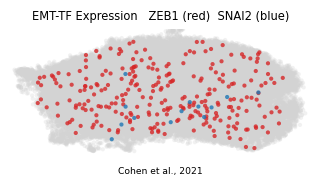

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in show_tfs:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in show_tfs}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in show_tfs},
      '| cells shown:', {g: int(sel[g].sum()) for g in show_tfs})
order = sorted(show_tfs, key=lambda g: -int(sel[g].sum()))
palette = ['tab:red','tab:blue']
colors = {g: palette[i] for i,g in enumerate(order)}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
lbl = '  '.join(f'{g} ({colors[g].split(chr(58))[1]})' for g in order)
ax.set_title(f'EMT-TF Expression   {lbl}', size=7.5)
ax.text(.5,-.14,'Cohen et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
plt.show()
for g in show_tfs:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
print('saved expression.pdf')